# HS524M Test 2 – Q2: Srinagar – Permanent vs Seasonal Surface Water, 1990–2021

Built using the workflow from Lectures 24–30 (filter → mask → annual collection → time slider → labelled GIF → reducers).

**Research question:** How have the areas of permanent and seasonal surface water inside Srinagar's urban boundary changed from 1990 to 2021?

| Item | Choice |
|---|---|
| Dataset | JRC Global Surface Water Yearly History, `JRC/GSW1_4/YearlyHistory` |
| Band | `waterClass`: 0 = no data, 1 = not water, 2 = seasonal water, 3 = permanent water |
| Resolution / time | 30 m, one image per year |
| Variable meaning | Annual water *occurrence class* from Landsat (permanent = water throughout the observed year, seasonal = water for part of it) |
| Not a measure of | water depth, volume, or water quality |

Run from the root of the GitHub repo. Outputs go to `assets/`, which `index.html` reads.

## 1. Libraries, authentication and initialisation

In [1]:
import os
import requests
import ee
import geemap
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from PIL import Image, ImageSequence

os.makedirs("assets/frames", exist_ok=True)
os.makedirs("data", exist_ok=True)

In [2]:
# Use "uisa-class" if you have access to the instructor's project;
# otherwise replace with the project ID you registered for Earth Engine.
PROJECT_ID = "coastal-cities-air-pollution"

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

print("Google Earth Engine initialized successfully.")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Google Earth Engine initialized successfully.


## 2. Study area – Srinagar boundary

Boundary source: Indian Urban Local Body boundaries (urban release), as provided for the course in **GeoJSONL** format (one GeoJSON feature per line). We read the original file directly, with no QGIS/shapefile conversion, so geometry and column names are untouched.

Note: there is also a **Srinagar in Uttarakhand**, so we filter by state code as well.

In [3]:
import json
import shapely

# Path to the ORIGINAL file given by the professor
geojsonl_path = r"C:\Users\shara\Downloads\SBM_ULBs.geojsonl\SBM_ULBs.geojsonl" 

try:
    ulb_gdf = gpd.read_file(geojsonl_path)
except Exception as err:
    # Fallback: read the file line by line (each line is one GeoJSON feature)
    print("gpd.read_file failed, reading line by line instead:", err)
    features = []
    with open(geojsonl_path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                features.append(json.loads(line))
    ulb_gdf = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")

if ulb_gdf.crs is None:
    ulb_gdf = ulb_gdf.set_crs(epsg=4326)

print("Rows:", len(ulb_gdf), "| CRS:", ulb_gdf.crs)
print(ulb_gdf.columns.tolist())
ulb_gdf.drop(columns="geometry").head()

Rows: 3373 | CRS: EPSG:4326
['objectid', 'stnm', 'stcode', 'distnm', 'distcode', 'ulbnm', 'ulbcode', 'remark', 'st_area(shape)', 'st_perimeter(shape)', 'geometry']


,objectid,stnm,stcode,distnm,distcode,ulbnm,ulbcode,remark,st_area(shape),st_perimeter(shape)
0,1,Gujarat,24,SURAT,492,BARDOLI,802634,Bardoli Np Map,0.000641,0.137439
1,3,Gujarat,24,ANAND,482,BORSAD,802568,Borsad ULB Boundry,0.001362,0.242197
2,4,Gujarat,24,BHAVNAGAR,481,TALAJA,802555,1,0.002206,0.224569
3,5,Gujarat,24,AHMEDABAD,474,DHOLKA,802486,,0.001048,0.198146
4,6,Gujarat,24,BHARUCH,488,JAMBUSAR,802604,Jambusar ULB City Map,0.003488,0.374491


In [4]:
# Column names seen in the file: ulbnm = ULB name, stcode = state code (1 = Jammu & Kashmir)
# If the original file uses different names, change them here after checking the list above.
NAME_COL = "ulbnm"
STATE_COL = "stcode"

for col in (NAME_COL, STATE_COL):
    assert col in ulb_gdf.columns, f"Column '{col}' not found - check the printed column list"

state_num = pd.to_numeric(ulb_gdf[STATE_COL], errors="coerce")

srinagar_gdf = ulb_gdf[
    ulb_gdf[NAME_COL].astype(str).str.contains("Srinagar", case=False, na=False)
    & (state_num == 1)
]

print("rows found:", len(srinagar_gdf))
assert len(srinagar_gdf) == 1, "Expected exactly one Srinagar (J&K) row"
srinagar_gdf.drop(columns="geometry")

rows found: 1


,objectid,stnm,stcode,distnm,distcode,ulbnm,ulbcode,remark,st_area(shape),st_perimeter(shape)
3336,109604,,1,SRINAGAR,10,SRINAGAR MUNICIPAL CORPORATION,800013,Yes,0.006348,0.303304


In [5]:
# Clean the geometry before sending it to Earth Engine:
# valid polygon, 2D (no Z values), only the name column kept (no NaN properties)
clean = srinagar_gdf[[NAME_COL, "geometry"]].copy().to_crs(epsg=4326)

g = clean.geometry.iloc[0]
print("before: type", g.geom_type, "| valid", g.is_valid, "| has Z", g.has_z, "| empty", g.is_empty)

clean["geometry"] = clean.geometry.apply(lambda geom_: shapely.force_2d(shapely.make_valid(geom_)))
clean = clean.explode(index_parts=False)
clean = clean[clean.geometry.geom_type == "Polygon"].dissolve(by=NAME_COL).reset_index()

g = clean.geometry.iloc[0]
print("after:  type", g.geom_type, "| valid", g.is_valid, "| has Z", g.has_z)
print("City area (km2):", round(clean.to_crs(32643).area.sum() / 1e6, 1))

clean.to_file("data/srinagar_boundary.geojson", driver="GeoJSON")

before: type Polygon | valid True | has Z False | empty False
after:  type Polygon | valid True | has Z False
City area (km2): 64.9


In [6]:
srinagar = geemap.geopandas_to_ee(clean)
geom = srinagar.geometry()

# Check on the Earth Engine side
print("features:", srinagar.size().getInfo())
print("area km2:", round(geom.area(maxError=1).divide(1e6).getInfo(), 1))

# Always check the boundary before starting the time-series analysis
Map = geemap.Map()
Map.centerObject(srinagar, 11)
Map.addLayer(srinagar, {"color": "blue"}, "Srinagar Boundary")
Map

features: 1
area km2: 65.0


Map(center=[34.10483488616928, 74.81841414582911], controls=(WidgetControl(options=['position', 'transparent_b…

## 3. Load the annual water collection (1990–2021)

Unlike the NDVI notebooks, **no cloud masking or compositing is needed**: JRC has already built one classified image per year. The same logic still applies - filter dates, keep one band, keep the same visualization for every year.

`waterClass = 0` (no data) is kept on purpose so we can report how much of the city was *not observed* each year.

In [7]:
years = list(range(1990, 2022))
year_labels = [str(y) for y in years]

def prepare_water(image):
    year = image.date().get("year")
    return (
        image.select("waterClass")
        .clip(geom)
        .set("year", year)
        .copyProperties(image, ["system:time_start"])
    )

water_collection = (
    ee.ImageCollection("JRC/GSW1_4/YearlyHistory")
    .filterDate("1990-01-01", "2022-01-01")
    .map(prepare_water)
    .sort("system:time_start")
)

print("Number of annual water images:", water_collection.size().getInfo())   # expected: 32

Number of annual water images: 32


## 4. One visualization for every year

Same colours in every frame, so a colour always means the same class.

In [8]:
water_vis = {
    "min": 0,
    "max": 3,
    "palette": ["b0b0b0", "f4f1ea", "5bc0eb", "0b3c8c"]   # no data, not water, seasonal, permanent
}

legend_dict = {
    "Permanent water": "0b3c8c",
    "Seasonal water": "5bc0eb",
    "Not water": "f4f1ea",
    "No data": "b0b0b0",
}

# First check: 1990 vs 2021
Map = geemap.Map()
Map.centerObject(srinagar, 11)
Map.addLayer(ee.Image(water_collection.filter(ee.Filter.eq("year", 1990)).first()), water_vis, "Water 1990")
Map.addLayer(ee.Image(water_collection.filter(ee.Filter.eq("year", 2021)).first()), water_vis, "Water 2021", shown=False)
Map.addLayer(srinagar, {"color": "black"}, "Srinagar Boundary")
Map.add_legend(title="JRC water class", legend_dict=legend_dict, position="bottomright")
Map

Map(center=[34.10483488616928, 74.81841414582911], controls=(WidgetControl(options=['position', 'transparent_b…

## 5. Interactive time slider (for use in the notebook)

`add_time_slider` works inside Jupyter only. For the website we export the same frames as images (section 9).

In [9]:
Map = geemap.Map()
Map.centerObject(srinagar, 11)

Map.add_time_slider(
    water_collection,
    water_vis,
    region=geom,
    layer_name="Annual water class",
    labels=year_labels,
    time_interval=1,
    position="bottomright"
)

Map.addLayer(srinagar, {"color": "black"}, "Srinagar Boundary")
Map.add_legend(title="JRC water class", legend_dict=legend_dict, position="bottomleft")
Map

Map(center=[34.10483488616928, 74.81841414582911], controls=(WidgetControl(options=['position', 'transparent_b…

## 6. Annual permanent and seasonal water area

For every year: sum `pixelArea` over pixels of each class inside the boundary (`reduceRegion`, scale = 30 m). The calculation is mapped over the collection on the server, so there is one request instead of 32.

The no-data area is tracked too, because snow, cloud and sparse early Landsat coverage can look like real change.

In [10]:
pixel_km2 = ee.Image.pixelArea().divide(1e6)

def yearly_areas(image):
    wc = image.select("waterClass")

    stack = ee.Image.cat([
        pixel_km2.updateMask(wc.eq(2)).rename("seasonal_km2"),
        pixel_km2.updateMask(wc.eq(3)).rename("permanent_km2"),
        pixel_km2.updateMask(wc.eq(1)).rename("notwater_km2"),
        pixel_km2.updateMask(wc.eq(0)).rename("nodata_km2"),
        pixel_km2.rename("total_km2"),
    ])

    values = stack.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom,
        scale=30,
        maxPixels=1e9,
        tileScale=4
    )

    return ee.Feature(None, values).set("year", image.get("year"))

area_fc = ee.FeatureCollection(water_collection.map(yearly_areas))

area_info = area_fc.getInfo()
df = pd.DataFrame([f["properties"] for f in area_info["features"]]).fillna(0)
df["year"] = df["year"].astype(int)
df = df.sort_values("year").reset_index(drop=True)

df["water_km2"] = df["seasonal_km2"] + df["permanent_km2"]
df["nodata_pct"] = 100 * df["nodata_km2"] / df["total_km2"]

df.round(3).to_csv("assets/area_by_year.csv", index=False)
df.round(3)

,nodata_km2,notwater_km2,permanent_km2,seasonal_km2,total_km2,year,water_km2,nodata_pct
0,8.841,0.048,1.120,1.051,64.967,1990,2.171,13.608
1,1.133,0.287,5.324,4.315,64.967,1991,9.639,1.744
2,0.899,0.209,5.376,4.576,64.967,1992,9.952,1.383
3,0.644,0.240,5.394,4.781,64.967,1993,10.175,0.991
4,0.485,0.564,5.334,4.676,64.967,1994,10.010,0.747
5,3.125,0.219,4.732,2.983,64.967,1995,7.714,4.810
6,0.937,0.409,5.381,4.332,64.967,1996,9.713,1.442
7,10.454,0.144,0.232,0.228,64.967,1997,0.461,16.091
8,0.395,0.958,4.969,4.737,64.967,1998,9.707,0.608
9,0.068,0.432,4.962,5.598,64.967,1999,10.560,0.104


## 7. Two-class area graph

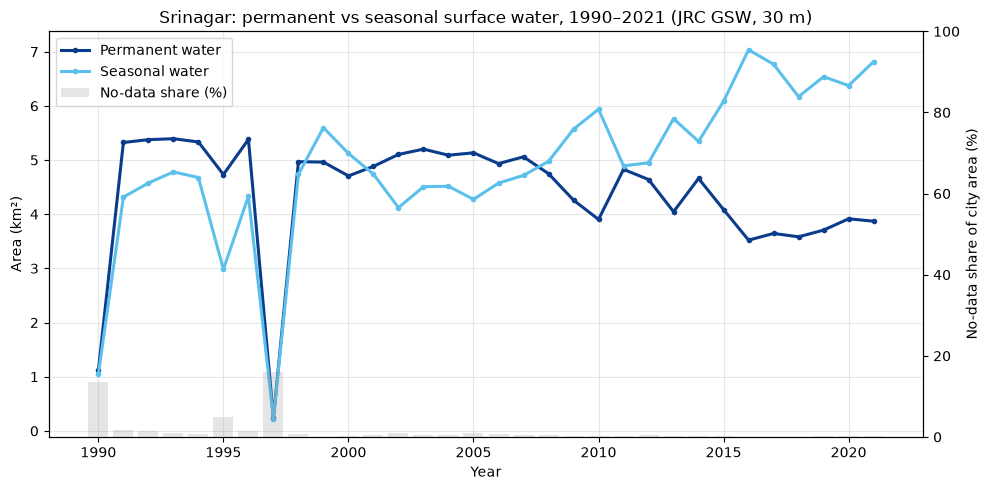

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df["year"], df["permanent_km2"], color="#0b3c8c", lw=2.2, marker="o", ms=3, label="Permanent water")
ax.plot(df["year"], df["seasonal_km2"],  color="#5bc0eb", lw=2.2, marker="o", ms=3, label="Seasonal water")
ax.set_xlabel("Year")
ax.set_ylabel("Area (km²)")
ax.set_title("Srinagar: permanent vs seasonal surface water, 1990–2021 (JRC GSW, 30 m)")
ax.grid(alpha=0.3)

ax2 = ax.twinx()
ax2.bar(df["year"], df["nodata_pct"], color="grey", alpha=0.2, width=0.8, label="No-data share (%)")
ax2.set_ylabel("No-data share of city area (%)")
ax2.set_ylim(0, 100)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")

plt.tight_layout()
plt.savefig("assets/area_timeseries.png", dpi=160)
plt.show()

## 8. Numerical summary

Never interpret a visual change without numbers. Three-year means at each end reduce the influence of one unusual year; the regression slope describes the whole series.

In [12]:
def summarise(col):
    first = df[col].head(3).mean()
    last = df[col].tail(3).mean()
    fit = stats.linregress(df["year"], df[col])
    return {
        "class": col.replace("_km2", ""),
        "mean_km2": df[col].mean(),
        "min_km2": df[col].min(),
        "min_year": int(df.loc[df[col].idxmin(), "year"]),
        "max_km2": df[col].max(),
        "max_year": int(df.loc[df[col].idxmax(), "year"]),
        "mean_1990_92": first,
        "mean_2019_21": last,
        "change_km2": last - first,
        "change_pct": 100 * (last - first) / first if first else np.nan,
        "trend_km2_per_year": fit.slope,
        "p_value": fit.pvalue,
    }

summary_df = pd.DataFrame(
    [summarise("permanent_km2"), summarise("seasonal_km2"), summarise("water_km2")]
).round(3)

summary_df.to_csv("assets/summary_stats.csv", index=False)
summary_df

,class,mean_km2,min_km2,min_year,max_km2,max_year,mean_1990_92,mean_2019_21,change_km2,change_pct,trend_km2_per_year,p_value
0,permanent,4.386,0.232,1997,5.394,1993,3.940,3.831,-0.109,-2.770,-0.017,0.443
1,seasonal,4.908,0.228,1997,7.035,2016,3.314,6.577,3.263,98.461,0.111,0.000
2,water,9.294,0.461,1997,10.688,2021,7.254,10.407,3.154,43.477,0.094,0.020


### Class transitions, 1990 → 2021

Only pixels observed (class ≠ 0) in **both** years are counted.

In [13]:
img_1990 = ee.Image(water_collection.filter(ee.Filter.eq("year", 1990)).first())
img_2021 = ee.Image(water_collection.filter(ee.Filter.eq("year", 2021)).first())

valid = img_1990.neq(0).And(img_2021.neq(0))
transition = img_1990.multiply(10).add(img_2021).rename("t")

groups = (
    pixel_km2.addBands(transition)
    .updateMask(valid)
    .reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName="t"),
        geometry=geom,
        scale=30,
        maxPixels=1e9,
        tileScale=4
    )
    .get("groups")
    .getInfo()
)

names = {1: "Not water", 2: "Seasonal", 3: "Permanent"}
rows = [{"from_1990": names[int(g["t"]) // 10],
         "to_2021": names[int(g["t"]) % 10],
         "area_km2": g["sum"]} for g in groups]

transition_df = (
    pd.DataFrame(rows)
    .pivot_table(index="from_1990", columns="to_2021", values="area_km2", fill_value=0)
    .round(3)
)
transition_df.to_csv("assets/transition_matrix_1990_2021.csv")
transition_df

to_2021,Not water,Permanent,Seasonal
from_1990,,,
Not water,0.003,0.018,0.027
Permanent,0.001,0.897,0.221
Seasonal,0.077,0.135,0.838


In [14]:
# Transition map
change_class = (
    ee.Image(0)
    .where(img_1990.eq(1).And(img_2021.eq(3)), 1)   # not water -> permanent
    .where(img_1990.eq(1).And(img_2021.eq(2)), 2)   # not water -> seasonal
    .where(img_1990.eq(2).And(img_2021.eq(3)), 3)   # seasonal  -> permanent
    .where(img_1990.eq(3).And(img_2021.eq(2)), 4)   # permanent -> seasonal
    .where(img_1990.eq(3).And(img_2021.eq(1)), 5)   # permanent -> not water
    .where(img_1990.eq(2).And(img_2021.eq(1)), 6)   # seasonal  -> not water
    .updateMask(valid)
)

change_vis = {"min": 1, "max": 6,
              "palette": ["0b3c8c", "5bc0eb", "1b9e77", "fdae61", "d7191c", "f4a6a6"]}

change_legend = {
    "Not water → permanent": "0b3c8c",
    "Not water → seasonal": "5bc0eb",
    "Seasonal → permanent": "1b9e77",
    "Permanent → seasonal": "fdae61",
    "Permanent → not water": "d7191c",
    "Seasonal → not water": "f4a6a6",
}

Map = geemap.Map()
Map.centerObject(srinagar, 11)
Map.addLayer(change_class, change_vis, "Water class change 1990–2021")
Map.addLayer(srinagar, {"color": "black"}, "Srinagar Boundary")
Map.add_legend(title="Change 1990 → 2021", legend_dict=change_legend, position="bottomright")
Map

Map(center=[34.10483488616928, 74.81841414582911], controls=(WidgetControl(options=['position', 'transparent_b…

In [15]:
# Static version of the transition map for the website
outline = ee.Image().byte().paint(srinagar, 1, 2).visualize(palette=["000000"])
white_bg = ee.Image.constant(1).visualize(min=0, max=1, palette=["ffffff"])

change_img = white_bg.blend(change_class.clip(geom).visualize(**change_vis)).blend(outline)

url = change_img.getThumbURL({"region": geom.bounds(), "dimensions": 900, "format": "png"})
with open("assets/transition_map.png", "wb") as f:
    f.write(requests.get(url, timeout=120).content)
print("Saved assets/transition_map.png")

Saved assets/transition_map.png


## 9. Animated GIF (Lecture 30 method) and frames for the web slider

Each annual image is converted to a three-band visual image with the **same** `water_vis`, drawn on a white background with the boundary outline. `download_ee_video` builds the GIF; `add_text_to_gif` adds the year and a progress bar.

In [16]:
def visualize_water(image):
    frame = (
        white_bg
        .blend(image.visualize(**water_vis))
        .blend(outline)
    )
    return frame.copyProperties(image, ["system:time_start", "year"])

water_gif_collection = water_collection.map(visualize_water)

gif_file = "assets/Srinagar_water_1990_2021.gif"

video_args = {
    "dimensions": 700,
    "region": geom.bounds(),
    "framesPerSecond": 2,
    "crs": "EPSG:3857",
    "bands": ["vis-red", "vis-green", "vis-blue"],
    "min": 0,
    "max": 255
}

geemap.download_ee_video(water_gif_collection, video_args, gif_file)

Generating URL...
Please wait ...
The GIF image has been saved to: C:\Users\shara\UISA_2026\assets\Srinagar_water_1990_2021.gif


In [17]:
labelled_gif = "assets/srinagar_water.gif"

geemap.add_text_to_gif(
    gif_file,
    labelled_gif,
    xy=("5%", "5%"),
    text_sequence=year_labels,
    font_size=30,
    font_color="black",
    add_progress_bar=True,
    progress_bar_color="black"
)

geemap.show_image(labelled_gif)

Output()

In [18]:
# Split the (unlabelled) GIF into one PNG per year: these drive the slider on the website
with Image.open(gif_file) as g:
    frames = [f.convert("RGB").copy() for f in ImageSequence.Iterator(g)]

print(len(frames), "frames found; expected", len(years))
for y, frame in zip(years, frames):
    frame.save(f"assets/frames/{y}.png")

32 frames found; expected 32


## 10. Discussion

Results come from `summary_stats.csv`, `area_by_year.csv` and `transition_matrix.csv`, organised with the reusable framework from class.

1. **Research question** – How did the area of permanent and seasonal surface water inside Srinagar's boundary (64.9 km²) change between 1991–93 and 2019–21?
2. **Variable** – The annual water-occurrence class (permanent, seasonal, not water), reported as area in km². It is not water depth or volume.
3. **Dataset** – JRC Global Surface Water v1.4, derived from Landsat, annual classes for 1990–2021.
4. **Spatial resolution** – Each 30 m pixel covers 0.0009 km², so narrow channels and small ponds are missed. JRC classifies only about 11 km² of the city, so water covers roughly 16% of Srinagar (10.4 km² in 2021).
5. **Temporal resolution** – Annual classes fold short floods and dry spells into one label, so seasonal water mixes several processes.
6. **Quality issues** – In 1990, 1995 and 1997, about 80%, 28% and 95% of the mapped area had no valid observation, so their very low values reflect missing data, not less water. These years are excluded from all averages and trends, and the baseline starts in 1991.
7. **Meaning** – "Permanent" and "seasonal" follow JRC definitions, not local hydrology, and the series ends in 2021.
8. **Defensible claims** –
   - Permanent water fell from 5.37 to 3.83 km² (−1.53 km², −28.6%). The decline is steady: the trend is −0.061 km² per year (p < 0.001), and period means fall from 5.18 km² (1991–2000) to 4.83 km² (2001–10) and 4.05 km² (2011–21).
   - Seasonal water rose from 4.56 to 6.58 km² (+44.3%, +0.076 km² per year, p < 0.001). It peaked in 2016 at 7.04 km², the same year permanent water reached its lowest value of 3.52 km².
   - Seasonal water is the more variable class, ranging from 4.12 km² (2002) to 7.04 km² (2016), compared with 3.52 to 5.39 km² for permanent water. Its period means were similar in 1991–2000 and 2001–10 (4.77 and 4.79 km²) and then rose to 6.07 km² in 2011–21, so the increase is concentrated in the last decade.
   - Total water changed little, from 9.92 to 10.41 km² (+4.9%), with a weak trend (+0.015 km² per year, p = 0.042, R² = 0.14). A 0.49 km² change is only about 540 pixels, so it should not be over-interpreted. The change is therefore in persistence, not quantity: seasonal water grew from about 45% to about 63% of all water.
   - The cause cannot be determined from this dataset. The classes depend on how many valid observations fall in each year, so part of the shift may come from observation frequency or water level rather than lasting loss of water. Explanations such as urbanisation or climate would need evidence beyond this analysis.

**Conclusion.** Srinagar's surface water stayed close to 10 km², but a growing share of it is seasonal rather than permanent.